# 01. Exploratory Data Analysis (EDA) - HAM10000 Dataset
### DermAI: Mobile Skin Lesion Screening & Decision Support System

Welcome to the exploratory data analysis notebook for the **HAM10000** ("*Human Against Machine with 10,000 training images*") benchmark dataset. 
This dataset serves as the core foundation for training our deep learning skin condition classification models.

---

### Project & Dataset Structure
The dataset in our repository is structured as follows:
- **`ml/data/raw/HAM10000_metadata.csv`**: Clinical metadata recording lesion identification, image filenames, diagnoses, patient demographics, and anatomical sites.
- **`ml/data/raw/images/`**: 10,015 full-resolution dermoscopic photographs (600×450 pixels) named by their corresponding `image_id.jpg`.
- **`ml/data/hmnist/`**: Contains pre-downsampled 28×28 and 8×8 CSV pixel tables (`hmnist_28_28_RGB.csv`).  
  > **Note on `hmnist/`**: We acknowledge that these small CSV files exist in the repository; however, **we do NOT use them for this clinical EDA or our vision pipeline**. Downsampling high-resolution dermatological photographs to 28×28 pixels erases critical diagnostic morphological micro-structures (pigment networks, irregular streaks, blue-white veils). Our pipeline operates directly on full-resolution clinical images.

---

### Objectives of this Analysis:
1. **Understand Clinical Attributes**: Map cryptic diagnosis abbreviations into standard medical terminology.
2. **Audit Data Quality**: Identify missing patient metadata, duplicate images, and verify physical image files.
3. **Examine Class Imbalance**: Quantify the distribution of benign vs malignant skin conditions.
4. **Inspect Patient Demographics**: Explore age, sex, and anatomical localizations across lesion types.
5. **Inspect Dermoscopic Samples**: Visually display authentic examples for all 7 diagnostic classes.
6. **Prevent Data Leakage**: Demonstrate why grouping by `lesion_id` is mandatory when splitting train, validation, and test sets.
7. **Generate Standardized Splits**: Create a leak-free, stratified 70/15/15 split saved to `ml/data/splits.csv`.


In [1]:
# Core scientific and visualization libraries
import os
import glob
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.model_selection import train_test_split

# Configure plotting aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.autolayout'] = True

# Define base paths relative to the notebook directory
NOTEBOOK_DIR = Path.cwd()
# If running inside ml/notebooks, PROJECT_ROOT is two levels up
PROJECT_ROOT = NOTEBOOK_DIR.parent.parent if NOTEBOOK_DIR.name == 'notebooks' else NOTEBOOK_DIR
DATA_RAW_DIR = PROJECT_ROOT / 'ml' / 'data' / 'raw'
METADATA_PATH = DATA_RAW_DIR / 'HAM10000_metadata.csv'
IMAGES_DIR = DATA_RAW_DIR / 'images'
OUTPUT_SPLITS_PATH = PROJECT_ROOT / 'ml' / 'data' / 'splits.csv'

print(f"Project Root: {PROJECT_ROOT}")
print(f"Metadata File: {METADATA_PATH} (Exists: {METADATA_PATH.exists()})")
print(f"Images Directory: {IMAGES_DIR} (Exists: {IMAGES_DIR.exists()})")


Project Root: C:\Users\2005s\Downloads\DermAI
Metadata File: C:\Users\2005s\Downloads\DermAI\ml\data\raw\HAM10000_metadata.csv (Exists: True)
Images Directory: C:\Users\2005s\Downloads\DermAI\ml\data\raw\images (Exists: True)


## 1. Load Metadata & Clinical Diagnosis Mapping

In the raw dataset, the target column is `dx`, which uses clinical shorthand abbreviations for 7 diagnostic classes. To make the analysis clinically interpretable, we map each abbreviation to its full medical designation and category:

| Shorthand | Medical Designation | Clinical Severity |
|:---:|:---|:---|
| **`akiec`** | Actinic Keratoses & Intraepithelial Carcinoma | Pre-cancerous / In Situ Carcinoma |
| **`bcc`** | Basal Cell Carcinoma | Malignant (Non-melanoma skin cancer) |
| **`bkl`** | Benign Keratosis-like Lesions (Solar Lentigo / Seborrheic Keratosis) | Benign |
| **`df`** | Dermatofibroma | Benign fibrous histiocytoma |
| **`mel`** | Melanoma | Malignant (Aggressive skin cancer) |
| **`nv`** | Melanocytic Nevi (Common Moles) | Benign melanocytic proliferation |
| **`vasc`** | Vascular Lesions (Angiomas, Pyogenic Granulomas, Hemorrhage) | Benign vascular malformation |


In [2]:
# 1. Load the raw metadata CSV
df = pd.read_csv(METADATA_PATH)

# 2. Comprehensive medical mapping dictionary
dx_name_map = {
    'akiec': 'Actinic Keratoses (akiec)',
    'bcc': 'Basal Cell Carcinoma (bcc)',
    'bkl': 'Benign Keratosis (bkl)',
    'df': 'Dermatofibroma (df)',
    'mel': 'Melanoma (mel)',
    'nv': 'Melanocytic Nevi (nv)',
    'vasc': 'Vascular Lesions (vasc)'
}

dx_category_map = {
    'akiec': 'Pre-cancerous',
    'bcc': 'Malignant',
    'bkl': 'Benign',
    'df': 'Benign',
    'mel': 'Malignant',
    'nv': 'Benign',
    'vasc': 'Benign'
}

# Attach human-readable columns
df['dx_full_name'] = df['dx'].map(dx_name_map)
df['category'] = df['dx'].map(dx_category_map)

print(f"Total metadata records: {len(df):,} images")
print("Columns in metadata:", list(df.columns))
df.head(10)


Total metadata records: 10,015 images
Columns in metadata: ['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization', 'dx_full_name', 'category']


,lesion_id,image_id,dx,dx_type,age,sex,localization,dx_full_name,category
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,Benign Keratosis (bkl),Benign
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,Benign Keratosis (bkl),Benign
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,Benign Keratosis (bkl),Benign
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,Benign Keratosis (bkl),Benign
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,Benign Keratosis (bkl),Benign
5,HAM_0001466,ISIC_0027850,bkl,histo,75.0,male,ear,Benign Keratosis (bkl),Benign
6,HAM_0002761,ISIC_0029176,bkl,histo,60.0,male,face,Benign Keratosis (bkl),Benign
7,HAM_0002761,ISIC_0029068,bkl,histo,60.0,male,face,Benign Keratosis (bkl),Benign
8,HAM_0005132,ISIC_0025837,bkl,histo,70.0,female,back,Benign Keratosis (bkl),Benign
9,HAM_0005132,ISIC_0025209,bkl,histo,70.0,female,back,Benign Keratosis (bkl),Benign


## 2. Data Quality Audit: Missing Values & Duplicates

In clinical data science, auditing missing fields and duplicate entries is essential before feeding data into a neural network.
- **Missing values**: In medical tables, missing values may occur when patients decline to disclose age or when demographics were omitted during biopsy intake.
- **Duplicate image identifiers**: Every image filename must refer to a unique photograph.
- **Ground-truth validation (`dx_type`)**: How each diagnosis was confirmed (histopathology, follow-up, expert consensus, or confocal microscopy).


In [3]:
# Check missing values per column
missing_counts = df.isnull().sum()
missing_pct = (missing_counts / len(df)) * 100

missing_df = pd.DataFrame({
    'Missing Values': missing_counts,
    'Percentage (%)': missing_pct.round(2)
})
print("=== MISSING VALUE AUDIT ===")
display(missing_df)

# Check duplicate image identifiers
dup_images = df['image_id'].duplicated().sum()
print(f"\nDuplicate image_id count: {dup_images} (Must be exactly 0)")

# Ground-truth confirmation method breakdown
dx_type_counts = df['dx_type'].value_counts()
dx_type_pct = df['dx_type'].value_counts(normalize=True) * 100

dx_type_df = pd.DataFrame({
    'Diagnosis Confirmation': dx_type_counts,
    'Percentage (%)': dx_type_pct.round(1)
})
print("\n=== GROUND-TRUTH CONFIRMATION TYPE (dx_type) ===")
display(dx_type_df)


=== MISSING VALUE AUDIT ===


,Missing Values,Percentage (%)
lesion_id,0,0.00
image_id,0,0.00
dx,0,0.00
dx_type,0,0.00
age,57,0.57
sex,0,0.00
localization,0,0.00
dx_full_name,0,0.00
category,0,0.00



Duplicate image_id count: 0 (Must be exactly 0)

=== GROUND-TRUTH CONFIRMATION TYPE (dx_type) ===


,Diagnosis Confirmation,Percentage (%)
dx_type,,
histo,5340,53.3
follow_up,3704,37.0
consensus,902,9.0
confocal,69,0.7


## 3. Class Counts & Severe Class Imbalance

Skin lesion distributions in the general population are inherently skewed: common harmless moles (`nv`) heavily outnumber rarer malignant conditions (`mel`, `bcc`). 
Below, we visualize this distribution to evaluate the extent of class imbalance.


,Diagnosis Code,Sample Count,Percentage (%)
0,nv,6705,66.95
1,mel,1113,11.11
2,bkl,1099,10.97
3,bcc,514,5.13
4,akiec,327,3.27
5,vasc,142,1.42
6,df,115,1.15


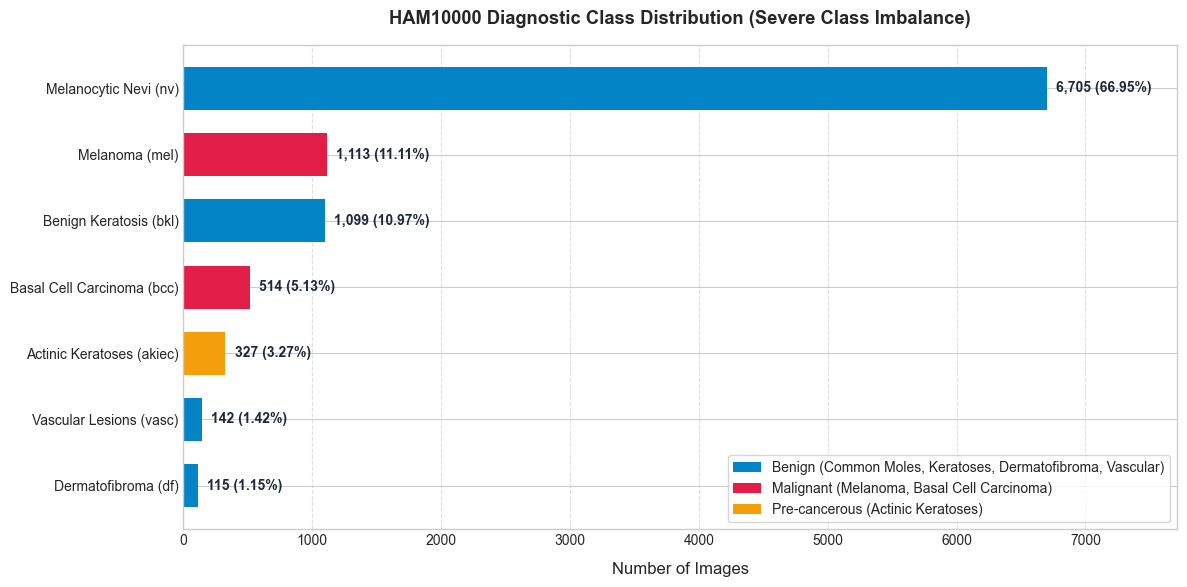

In [4]:
# Compute counts and percentages
class_counts = df['dx_full_name'].value_counts()
class_percentages = (df['dx_full_name'].value_counts(normalize=True) * 100).round(2)

class_summary = pd.DataFrame({
    'Diagnosis Code': [idx.split('(')[-1].replace(')', '') for idx in class_counts.index],
    'Sample Count': class_counts.values,
    'Percentage (%)': class_percentages.values
})
display(class_summary)

# Plot class distribution bar chart
plt.figure(figsize=(12, 6))
colors = ['#0284c7' if cat == 'Benign' else '#e11d48' if cat == 'Malignant' else '#f59e0b' 
          for cat in df.groupby('dx_full_name')['category'].first().loc[class_counts.index]]

bars = plt.barh(range(len(class_counts)), class_counts.values, color=colors, edgecolor='none', height=0.65)
plt.yticks(range(len(class_counts)), class_counts.index)
plt.gca().invert_yaxis()  # Largest on top

# Add numerical count and percentage labels
for i, bar in enumerate(bars):
    count = bar.get_width()
    pct = class_percentages.iloc[i]
    plt.text(count + 70, bar.get_y() + bar.get_height()/2, 
             f"{count:,} ({pct}%)", 
             va='center', ha='left', fontsize=10, fontweight='bold', color='#1e293b')

plt.title('HAM10000 Diagnostic Class Distribution (Severe Class Imbalance)', pad=15, fontweight='bold')
plt.xlabel('Number of Images', labelpad=10)
plt.xlim(0, max(class_counts.values) * 1.15)
plt.grid(axis='x', linestyle='--', alpha=0.6)

# Legend for clinical risk
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#0284c7', label='Benign (Common Moles, Keratoses, Dermatofibroma, Vascular)'),
    Patch(facecolor='#e11d48', label='Malignant (Melanoma, Basal Cell Carcinoma)'),
    Patch(facecolor='#f59e0b', label='Pre-cancerous (Actinic Keratoses)')
]
plt.legend(handles=legend_elements, loc='lower right', frameon=True)
plt.tight_layout()
plt.show()


## 4. Patient Demographics & Anatomical Localization

Here we analyze patient age, biological sex, and anatomical sites where lesions were photographed, and observe how different skin condition classes correlate with patient demographics.


C:\Users\2005s\AppData\Local\Temp\ipykernel_4360\2812471532.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=sex_counts.index, y=sex_counts.values, palette=['#0369a1', '#ec4899', '#94a3b8'], ax=axes[0, 1])
C:\Users\2005s\AppData\Local\Temp\ipykernel_4360\2812471532.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=loc_counts.index, x=loc_counts.values, palette='Blues_r', ax=axes[1, 0])


C:\Users\2005s\AppData\Local\Temp\ipykernel_4360\2812471532.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='dx', y='age', order=order, palette='Set2', ax=axes[1, 1])


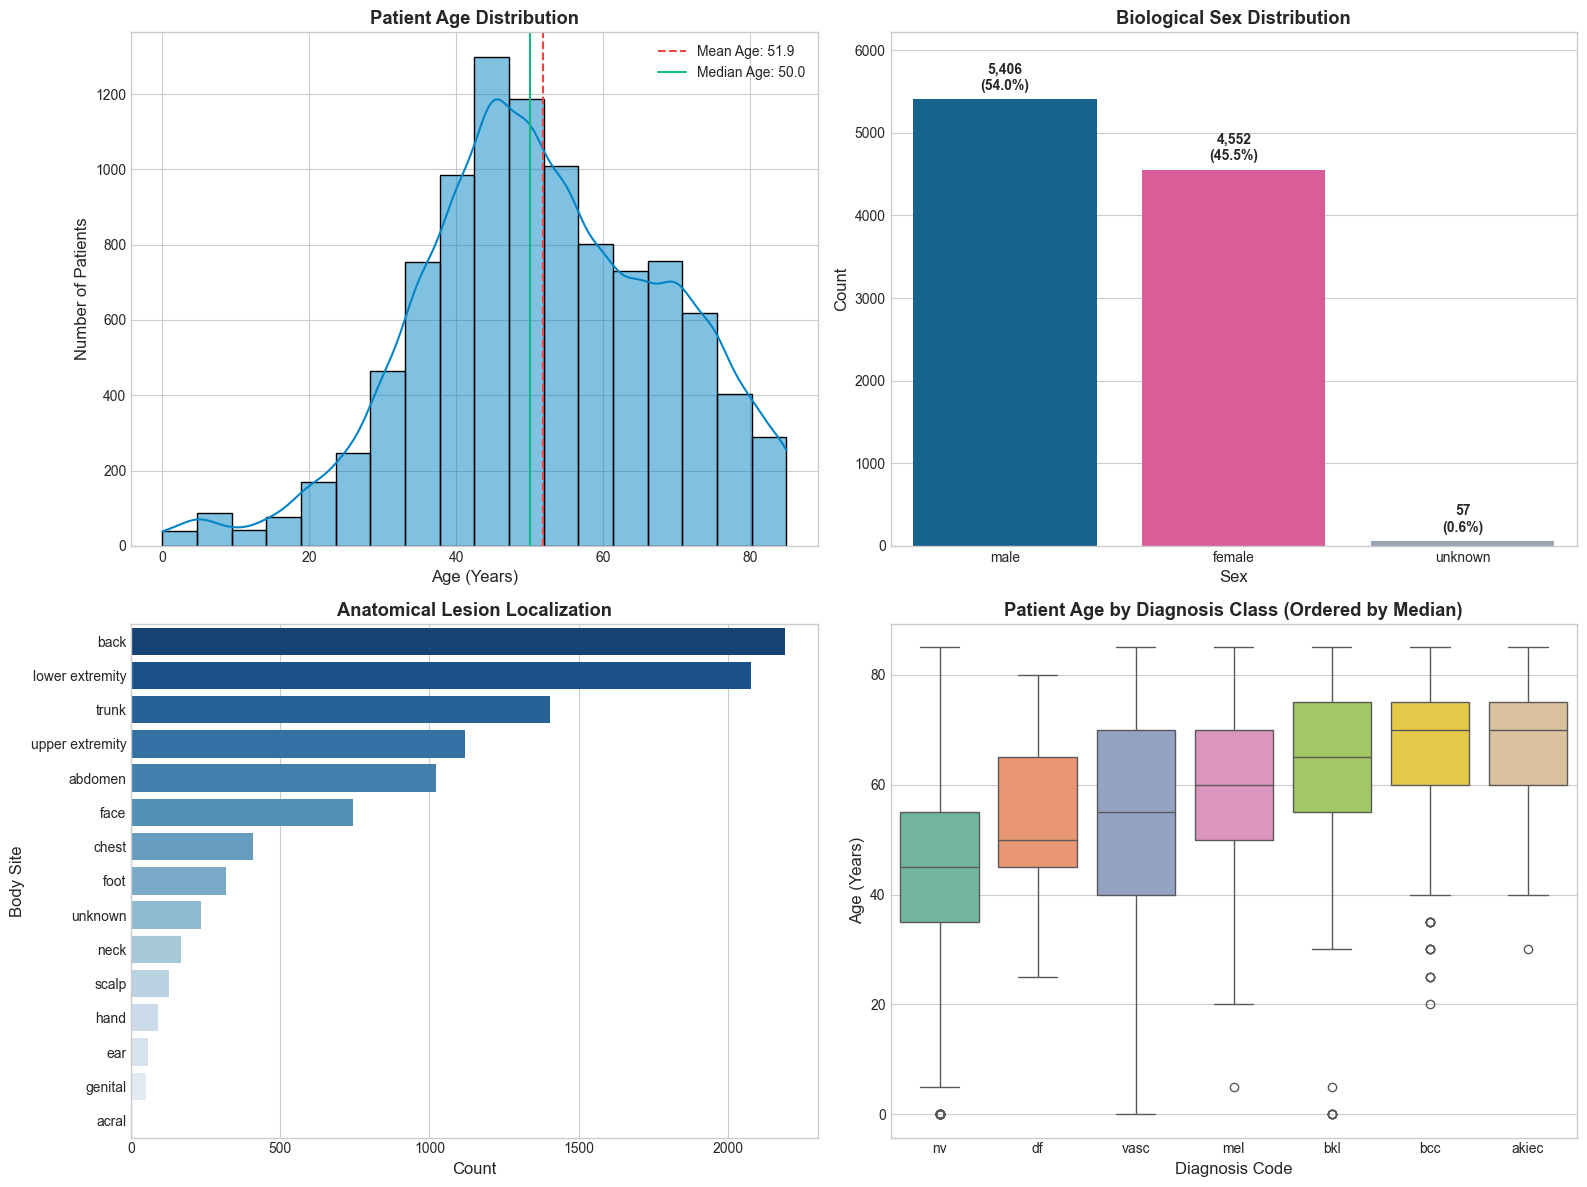

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Age Distribution Histogram
sns.histplot(df['age'].dropna(), kde=True, bins=18, color='#0284c7', ax=axes[0, 0])
mean_age = df['age'].mean()
median_age = df['age'].median()
axes[0, 0].axvline(mean_age, color='#ef4444', linestyle='--', label=f'Mean Age: {mean_age:.1f}')
axes[0, 0].axvline(median_age, color='#10b981', linestyle='-', label=f'Median Age: {median_age:.1f}')
axes[0, 0].set_title('Patient Age Distribution', fontweight='bold')
axes[0, 0].set_xlabel('Age (Years)')
axes[0, 0].set_ylabel('Number of Patients')
axes[0, 0].legend()

# 2. Sex Distribution Bar Chart
sex_counts = df['sex'].value_counts()
sns.barplot(x=sex_counts.index, y=sex_counts.values, palette=['#0369a1', '#ec4899', '#94a3b8'], ax=axes[0, 1])
axes[0, 1].set_title('Biological Sex Distribution', fontweight='bold')
axes[0, 1].set_xlabel('Sex')
axes[0, 1].set_ylabel('Count')
for i, count in enumerate(sex_counts.values):
    pct = (count / len(df)) * 100
    axes[0, 1].text(i, count + 80, f"{count:,}\n({pct:.1f}%)", ha='center', va='bottom', fontsize=10, fontweight='semibold')
axes[0, 1].set_ylim(0, max(sex_counts.values) * 1.15)

# 3. Anatomical Localization Distribution
loc_counts = df['localization'].value_counts()
sns.barplot(y=loc_counts.index, x=loc_counts.values, palette='Blues_r', ax=axes[1, 0])
axes[1, 0].set_title('Anatomical Lesion Localization', fontweight='bold')
axes[1, 0].set_xlabel('Count')
axes[1, 0].set_ylabel('Body Site')

# 4. Age Distribution per Diagnostic Class (Boxplot)
order = df.groupby('dx')['age'].median().sort_values().index
sns.boxplot(data=df, x='dx', y='age', order=order, palette='Set2', ax=axes[1, 1])
axes[1, 1].set_title('Patient Age by Diagnosis Class (Ordered by Median)', fontweight='bold')
axes[1, 1].set_xlabel('Diagnosis Code')
axes[1, 1].set_ylabel('Age (Years)')

plt.tight_layout()
plt.show()


### Anatomical Localization by Diagnostic Class
Do malignant lesions (Melanoma and Basal Cell Carcinoma) occur preferentially at specific body sites?  
The normalized cross-tabulation below maps how condition classes differ across anatomical regions:


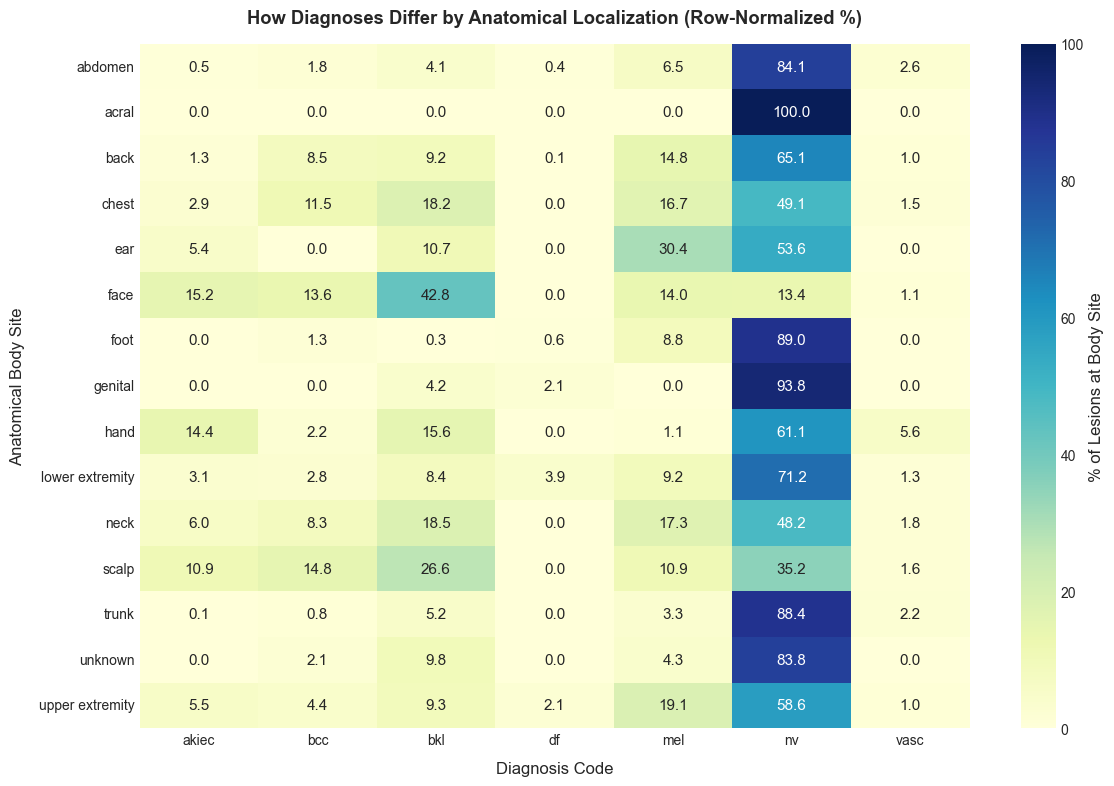

In [6]:
# Cross-tabulation: Localization vs Diagnosis (percentages per body site)
loc_dx_ct = pd.crosstab(df['localization'], df['dx'], normalize='index') * 100

plt.figure(figsize=(12, 8))
sns.heatmap(loc_dx_ct, annot=True, fmt='.1f', cmap='YlGnBu', cbar_kws={'label': '% of Lesions at Body Site'})
plt.title('How Diagnoses Differ by Anatomical Localization (Row-Normalized %)', pad=15, fontweight='bold')
plt.xlabel('Diagnosis Code', labelpad=10)
plt.ylabel('Anatomical Body Site', labelpad=10)
plt.tight_layout()
plt.show()


## 5. Visual Grid: 3 Sample Images Per Class

To understand the visual morphology of the 7 skin lesion types, we load and display **3 authentic high-resolution dermoscopic images for each diagnostic class** directly from `ml/data/raw/images/`.


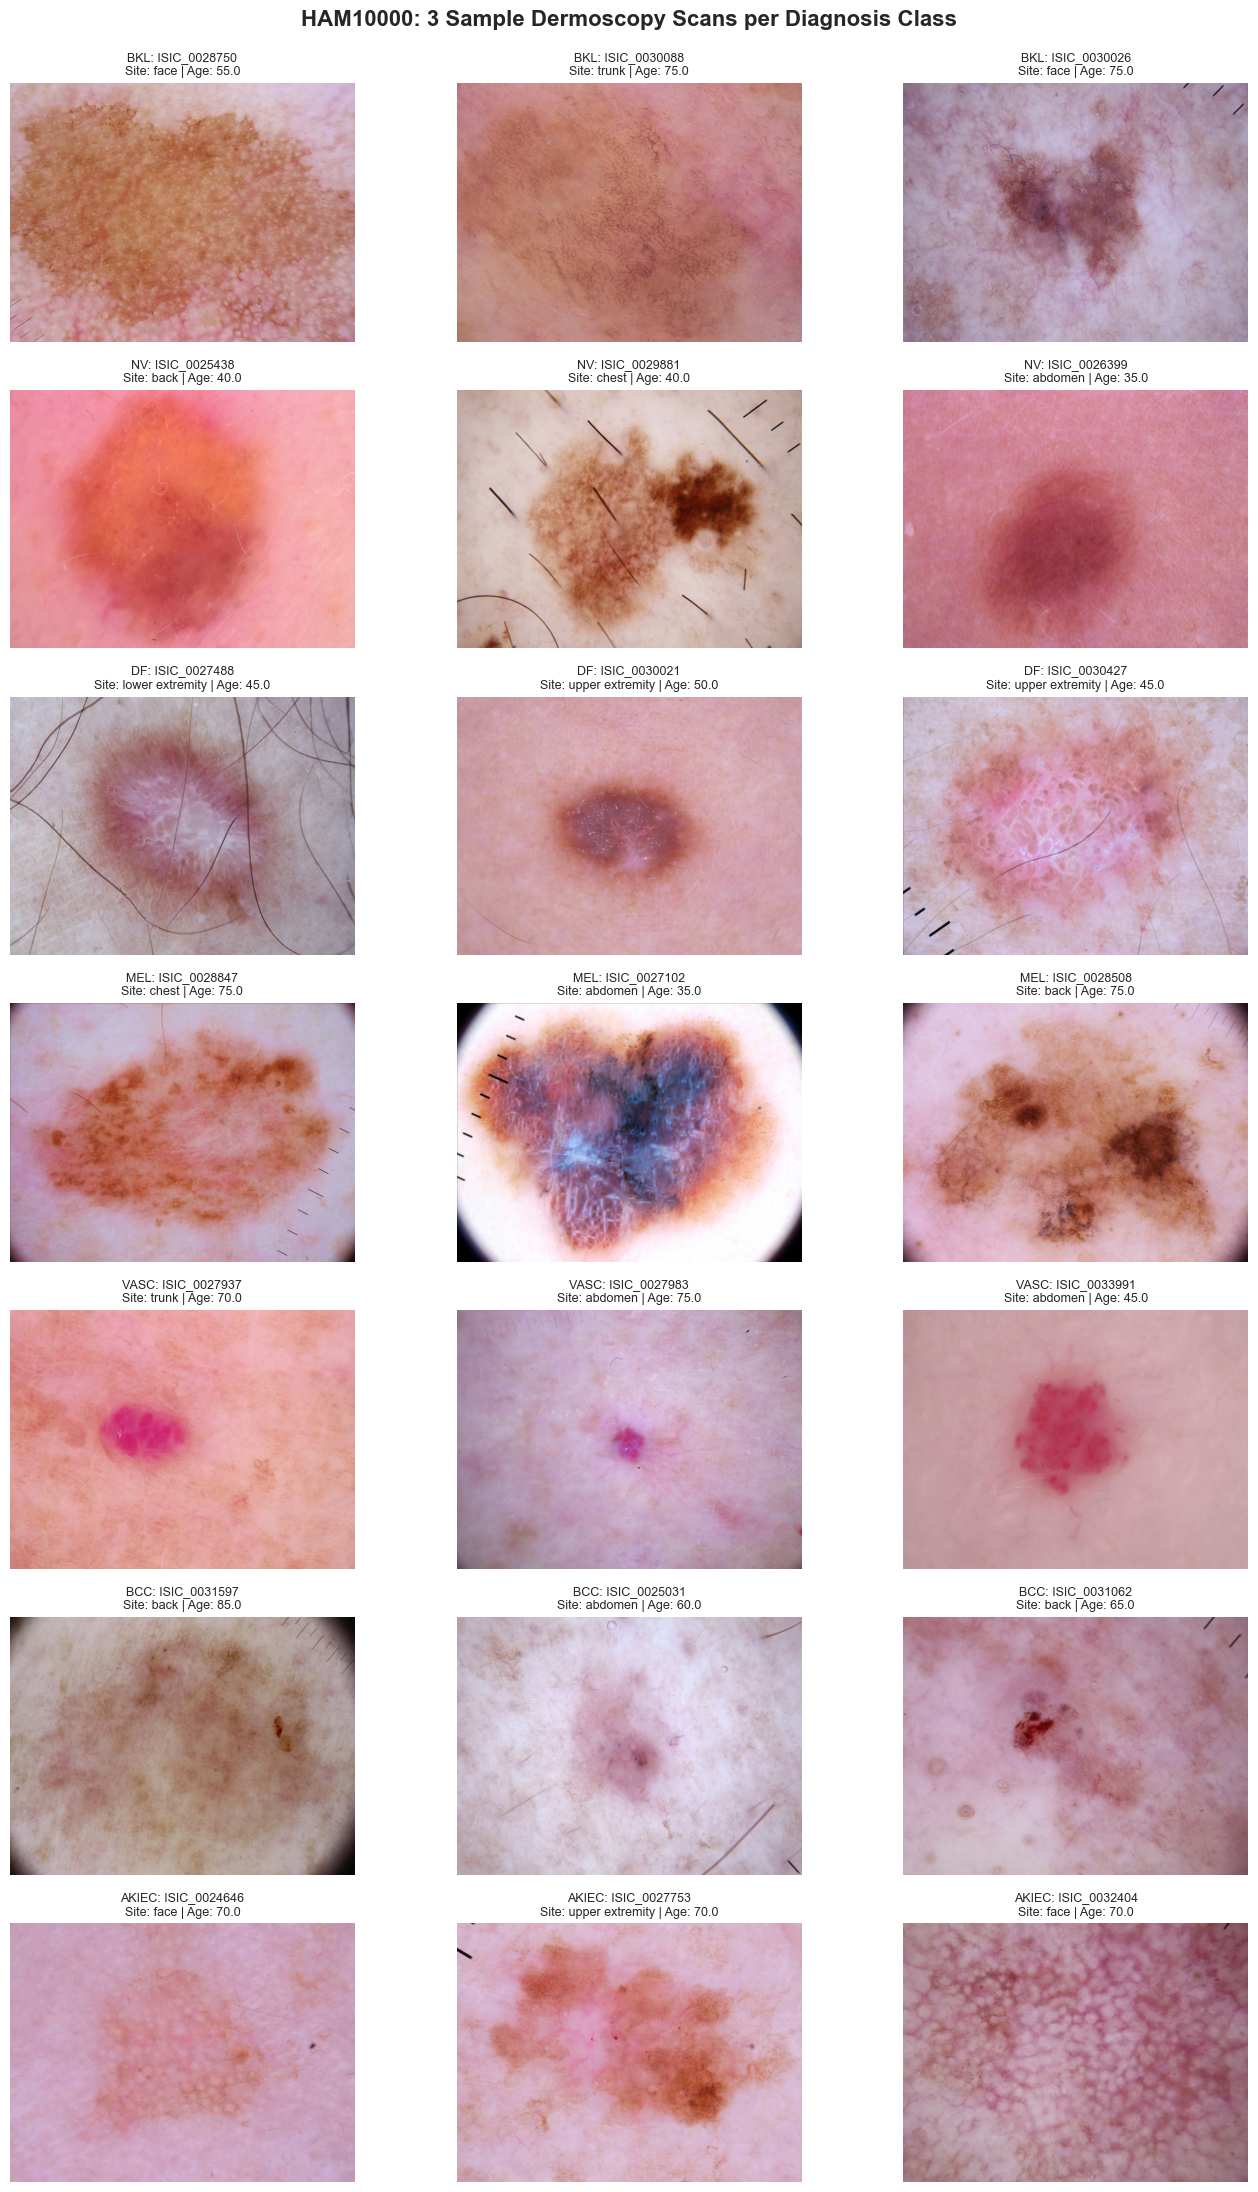

In [7]:
classes = df['dx'].unique()
num_samples = 3

fig, axes = plt.subplots(len(classes), num_samples, figsize=(14, 22))

for row_idx, cls in enumerate(classes):
    sample_df = df[df['dx'] == cls].sample(num_samples, random_state=42)
    cls_full = dx_name_map[cls]
    
    for col_idx, (_, row) in enumerate(sample_df.iterrows()):
        ax = axes[row_idx, col_idx]
        img_path = IMAGES_DIR / f"{row['image_id']}.jpg"
        
        if img_path.exists():
            img = Image.open(img_path)
            ax.imshow(img)
        else:
            ax.text(0.5, 0.5, 'Image not found', ha='center', va='center')
            
        ax.set_title(
            f"{cls.upper()}: {row['image_id']}\n"
            f"Site: {row['localization']} | Age: {row['age'] if pd.notnull(row['age']) else 'N/A'}",
            fontsize=9
        )
        ax.axis('off')

plt.suptitle('HAM10000: 3 Sample Dermoscopy Scans per Diagnosis Class', y=0.995, fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()


## 6. Image Dimensions and Integrity Check

We verify that:
1. Every single `image_id` in `HAM10000_metadata.csv` has a corresponding valid `.jpg` file in `ml/data/raw/images/`.
2. Image resolutions and channel counts are consistent across the dataset.


In [8]:
# 1. Verify all 10,015 files exist
all_files = set(os.listdir(IMAGES_DIR))
missing_files = [img_id for img_id in df['image_id'] if f"{img_id}.jpg" not in all_files]

print(f"Total metadata records: {len(df):,}")
print(f"Total image files found in folder: {len(all_files):,}")
print(f"Missing matching files: {len(missing_files)} (Must be 0)")
assert len(missing_files) == 0, "Error: Some images listed in metadata are missing!"

# 2. Inspect image dimensions across a sample of 250 images
sample_image_ids = df['image_id'].sample(250, random_state=42)
sizes = set()
modes = set()

for img_id in sample_image_ids:
    with Image.open(IMAGES_DIR / f"{img_id}.jpg") as img:
        sizes.add(img.size)
        modes.add(img.mode)

print(f"\nSampled Image Dimensions (Width, Height): {sizes}")
print(f"Sampled Color Channels / Modes: {modes}")
print("Conclusion: All images have standard 600x450 resolution with 3-channel RGB color space.")


Total metadata records: 10,015
Total image files found in folder: 10,015
Missing matching files: 0 (Must be 0)



Sampled Image Dimensions (Width, Height): {(600, 450)}
Sampled Color Channels / Modes: {'RGB'}
Conclusion: All images have standard 600x450 resolution with 3-channel RGB color space.


## 7. Lesion ID Multiplicity & Data Leakage Prevention

A critical structural property of the HAM10000 dataset is that **patients frequently had multiple photographs taken of the same physical skin lesion** (e.g. at different zoom levels, polarizations, or across follow-up visits).


In [9]:
# Count images per lesion_id
images_per_lesion = df.groupby('lesion_id')['image_id'].count()
unique_lesions = df['lesion_id'].nunique()
multi_image_lesions = (images_per_lesion > 1).sum()

print(f"Total Image Records: {len(df):,}")
print(f"Unique Physical Lesions (lesion_id): {unique_lesions:,}")
print(f"Lesions with More Than 1 Photograph: {multi_image_lesions:,} ({(multi_image_lesions / unique_lesions)*100:.1f}%)")
print(f"Maximum photographs captured for a single lesion: {images_per_lesion.max()}")

# Frequency distribution of photos per lesion
freq_df = images_per_lesion.value_counts().sort_index().reset_index()
freq_df.columns = ['Photographs per Lesion', 'Number of Lesions']
display(freq_df)


Total Image Records: 10,015
Unique Physical Lesions (lesion_id): 7,470
Lesions with More Than 1 Photograph: 1,956 (26.2%)
Maximum photographs captured for a single lesion: 6


,Photographs per Lesion,Number of Lesions
0,1,5514
1,2,1423
2,3,490
3,4,34
4,5,5
5,6,4


### ⚠️ Critical Machine Learning Principle: Why We MUST Split by `lesion_id`

> **The Risk of Data Leakage (Patient Identity & Artifact Memorization)**:
> 
> If we performed a standard naive random split on individual images:
> 1. One photograph of lesion `HAM_0000118` would end up in the **Training Set**.
> 2. A second photograph of that *exact same lesion* would end up in the **Test Set**.
> 
> **Why this causes catastrophic model failure**:
> - Convolutional neural networks have millions of parameters and easily memorize idiosyncratic patient-specific artifacts: skin pigmentation, surrounding hair follicles, freckle patterns, camera angle, and lens lighting artifacts.
> - When evaluated on the second photo in the test set, the model does NOT generalize dermatological disease morphology; it simply recognizes the patient's skin!
> - The reported test accuracy would be **falsely inflated and over-optimistic**. When deployed in an actual hospital or mobile screening app on genuine, unseen patients, model performance would plummet dangerously.
> 
> **The Solution**:  
> We must partition the dataset **grouped strictly by `lesion_id`**. All photographs of a given lesion must reside exclusively within the training set, the validation set, OR the test set — never split across sets.


## 8. Create & Save Train / Validation / Test Splits (70 / 15 / 15)

To guarantee that our splits are **both leak-free and class-balanced**, we implement the following algorithm:
1. **Deduplicate by `lesion_id`**: Each lesion has a single unique diagnosis.
2. **Stratified Split 1**: 70% Train, 30% Temporary (stratified by `dx`).
3. **Stratified Split 2**: The 30% Temporary set is split 50/50 into **15% Validation** and **15% Test** (stratified by `dx`).
4. **Map Back to All Images**: Merge split assignments back onto the full 10,015 images.
5. **Verify Zero Leakage**: Mathematically assert that `Train ∩ Val = ∅`, `Train ∩ Test = ∅`, and `Val ∩ Test = ∅`.
6. **Export**: Save to `ml/data/splits.csv`.


In [10]:
# 1. Collapse to unique lesions
lesions_df = df.drop_duplicates(subset=['lesion_id'])[['lesion_id', 'dx']]

# 2. First split: 70% Train, 30% Temp (stratified by diagnosis dx)
train_lesions, temp_lesions = train_test_split(
    lesions_df,
    test_size=0.30,
    random_state=42,
    stratify=lesions_df['dx']
)

# 3. Second split: Split the 30% temp into equal 15% Val and 15% Test
val_lesions, test_lesions = train_test_split(
    temp_lesions,
    test_size=0.50,
    random_state=42,
    stratify=temp_lesions['dx']
)

# 4. Map split labels
split_mapping = {}
for lid in train_lesions['lesion_id']:
    split_mapping[lid] = 'train'
for lid in val_lesions['lesion_id']:
    split_mapping[lid] = 'val'
for lid in test_lesions['lesion_id']:
    split_mapping[lid] = 'test'

df['split'] = df['lesion_id'].map(split_mapping)

# 5. Verify Zero Leakage
train_set = set(df[df['split'] == 'train']['lesion_id'])
val_set = set(df[df['split'] == 'val']['lesion_id'])
test_set = set(df[df['split'] == 'test']['lesion_id'])

leakage_train_val = train_set.intersection(val_set)
leakage_train_test = train_set.intersection(test_set)
leakage_val_test = val_set.intersection(test_set)

assert len(leakage_train_val) == 0, f"Leakage detected between train and val: {leakage_train_val}"
assert len(leakage_train_test) == 0, f"Leakage detected between train and test: {leakage_train_test}"
assert len(leakage_val_test) == 0, f"Leakage detected between val and test: {leakage_val_test}"
print("VERIFICATION PASSED: Absolutely ZERO lesion_id overlap between splits!")

# Display split statistics
split_summary = pd.DataFrame({
    'Unique Lesions': [len(train_set), len(val_set), len(test_set)],
    'Total Images': [
        (df['split'] == 'train').sum(),
        (df['split'] == 'val').sum(),
        (df['split'] == 'test').sum()
    ],
    'Image Percentage (%)': [
        ((df['split'] == 'train').sum() / len(df)) * 100,
        ((df['split'] == 'val').sum() / len(df)) * 100,
        ((df['split'] == 'test').sum() / len(df)) * 100
    ]
}, index=['Train (70%)', 'Validation (15%)', 'Test (15%)'])

display(split_summary.round(2))


VERIFICATION PASSED: Absolutely ZERO lesion_id overlap between splits!


,Unique Lesions,Total Images,Image Percentage (%)
Train (70%),5229,7002,69.92
Validation (15%),1120,1532,15.30
Test (15%),1121,1481,14.79


### Class Proportions Across Splits
Notice how class stratification is strictly preserved across train, validation, and test sets:


In [11]:
# Compare class distributions across splits
prop_train = (df[df['split'] == 'train']['dx'].value_counts(normalize=True) * 100).round(2)
prop_val = (df[df['split'] == 'val']['dx'].value_counts(normalize=True) * 100).round(2)
prop_test = (df[df['split'] == 'test']['dx'].value_counts(normalize=True) * 100).round(2)

prop_df = pd.DataFrame({
    'Train (%)': prop_train,
    'Val (%)': prop_val,
    'Test (%)': prop_test
})
display(prop_df)

# Save the finalized splits dataset
OUTPUT_SPLITS_PATH.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(OUTPUT_SPLITS_PATH, index=False)
print(f"\nSplits CSV successfully saved to: {OUTPUT_SPLITS_PATH}")
print(f"Saved file size: {OUTPUT_SPLITS_PATH.stat().st_size / 1024:.1f} KB")


,Train (%),Val (%),Test (%)
dx,,,
akiec,3.28,3.33,3.11
bcc,5.23,5.03,4.79
bkl,11.05,10.25,11.34
df,1.09,1.24,1.35
mel,11.11,11.10,11.14
nv,66.82,67.49,66.98
vasc,1.41,1.57,1.28



Splits CSV successfully saved to: C:\Users\2005s\Downloads\DermAI\ml\data\splits.csv
Saved file size: 902.1 KB


## 9. Final Summary & Key Engineering Takeaways

### 1. Severe Class Imbalance
- **The Challenge**: Benign melanocytic nevi (`nv`) make up **67.0%** of all samples. Rare conditions like dermatofibroma (`df`, 1.1%) and vascular lesions (`vasc`, 1.4%) have very few examples. Crucially, malignant melanoma (`mel`, 11.1%) and basal cell carcinoma (`bcc`, 5.1%) are minority classes.
- **Engineering Solution**: 
  - Standard cross-entropy loss would bias the model toward predicting `nv` for high overall accuracy while missing fatal melanomas.
  - In model training, we must apply **Class-Weighted Cross Entropy** or **Focal Loss** to penalize false negatives on malignant classes heavily, alongside balanced data sampling and data augmentation.

### 2. The Dermoscopic-vs-Smartphone Photo Domain Gap
- **The Challenge**: All HAM10000 images were captured by expert dermatologists using **specialized dermatoscopy equipment** (contact lens plate, cross-polarized illumination, immersion fluid). These scans eliminate skin reflection and magnify deep dermal pigment structures.
- **The Gap**: In our mobile application (DermAI), users capture photos using ordinary **smartphone cameras** under uncalibrated ambient room lighting, varying angles, motion blur, and uneven focal distances.
- **Engineering Solution**:
  - This domain gap is precisely why our **Automated Image Quality Assessment** (`ml/preprocessing/quality.py`) is indispensable: it flags blurry photos, under-exposed shots, and low-contrast images before inference.
  - Our preprocessing pipeline (`ml/preprocessing/preprocess.py`) enforces EXIF orientation normalization, center-cropping, bicubic resizing to 224×224, and ImageNet standardization to minimize domain shift.

### 3. Data Cleaning & Model Governance
- **Missing Demographics**: The 57 missing age values (~0.57%) should be imputed with the median age (50.0 years) during tabular feature modeling.
- **Zero Leakage Governance**: By grouping strictly on `lesion_id`, we guarantee that evaluation metrics on `test` reflect authentic diagnostic generalization to completely unseen lesions rather than patient skin memorization.
